In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn imports
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_curve, auc

# SMOTE import
from imblearn.over_sampling import SMOTE

# Load dataset
data = pd.read_csv("/content/synthetic_handover_data (3).csv")
print(data.head())
print("Dataset Columns:", data.columns)

# Strip spaces from column names
data.columns = data.columns.str.strip()

# Check the column names after stripping spaces
print("Cleaned Dataset Columns:", data.columns)

# Select  features
ai_features = ["DL", "UL", "RSSI", "rsrq", "rsrp", "nrxsrp", "nrxsrq", "snr", "CQI", "speed"]

# Check if all the features exist in the dataset
missing_features = [feature for feature in ai_features if feature not in data.columns]
if missing_features:
    print(f"Warning: The following features are missing in the dataset: {missing_features}")
else:
    # Proceed if no missing features
    X = data[ai_features]
    y = data["Handover"]

    # Check and handle missing values in X
    print("Missing values in X before cleaning:\n", X.isnull().sum())
    X = X.fillna(X.mean())  # Filling NaN values with column mean
    print("Missing values in X after cleaning:\n", X.isnull().sum())

    # Remove samples where y is NaN
    valid_indices = y.dropna().index
    X = X.loc[valid_indices]
    y = y.loc[valid_indices]

    # Split data into train and test sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    # Apply SMOTE only on training data
    smote = SMOTE(random_state=42)
    X_train, y_train = smote.fit_resample(X_train, y_train)

    # Train the Random Forest model
    rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
    rf_model.fit(X_train, y_train)

    # Predict on the test set
    y_pred = rf_model.predict(X_test)

    # Evaluate the model
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Accuracy: {accuracy:.2f}")
    print("Classification Report:\n", classification_report(y_test, y_pred))


      DL     UL   RSSI   rsrq   rsrp  nrxsrp  nrxsrq    snr    CQI  speed  \
0  25.23   2.44 -45.38  -3.42 -57.72  -89.96  -12.25   3.19  13.63  37.23   
1  24.30   1.00 -64.31 -20.00 -72.32  -86.11  -13.38   2.58   0.00  50.00   
2  22.53   4.83 -59.57  -3.00 -90.11  -81.51  -14.58  19.72  15.00   7.31   
3  26.09   5.96 -57.94 -20.00 -86.62  -78.14  -17.78   1.00  10.77   5.00   
4  25.32  15.00 -53.35  -4.48 -85.80  -73.24  -18.16   1.00  14.93   5.00   

   ...  transition_flag_UL  transition_flag_rssi  transition_flag_rsrq  \
0  ...                   0                     0                     1   
1  ...                   0                     0                     1   
2  ...                   0                     0                     1   
3  ...                   0                     0                     1   
4  ...                   0                     0                     0   

   transition_flag_rsrp  transition_flag_nrxsrp  transition_flag_nrxsrq  \
0                

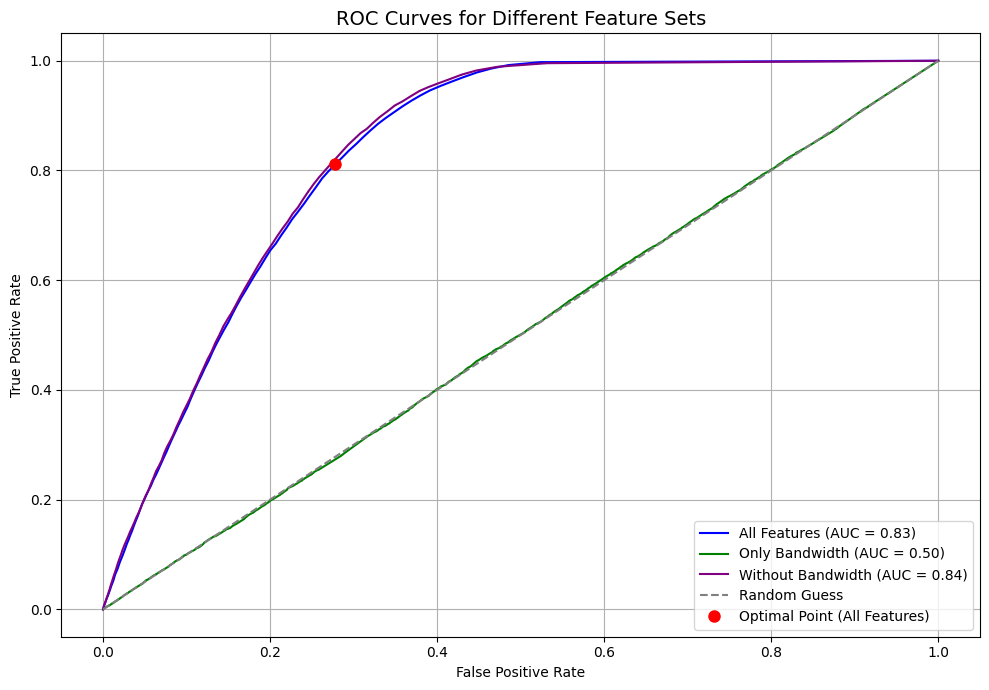

In [2]:
# Comparing Feature Sets

# Define feature sets
bandwidth_features = ["DL", "UL"]
other_features = ["RSSI", "rsrq", "rsrp", "nrxsrp", "nrxsrq", "snr", "CQI", "speed"]
all_features = bandwidth_features + other_features
target = "Handover"

# Prepare datasets
X_all = data[all_features]
X_band = data[bandwidth_features]
X_no_band = data[other_features]
y = data[target]

# Drop rows where y is NaN
valid_indices = y.dropna().index
X_all = X_all.loc[valid_indices]
X_band = X_band.loc[valid_indices]
X_no_band = X_no_band.loc[valid_indices]
y = y.loc[valid_indices]

# Split datasets
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(X_all, y, test_size=0.2, random_state=42, stratify=y)
X_train_band, X_test_band, y_train_band, y_test_band = train_test_split(X_band, y, test_size=0.2, random_state=42, stratify=y)
X_train_no_band, X_test_no_band, y_train_no_band, y_test_no_band = train_test_split(X_no_band, y, test_size=0.2, random_state=42, stratify=y)

# Apply SMOTE separately for each training set
smote = SMOTE(random_state=42)
X_train_all, y_train_all = smote.fit_resample(X_train_all, y_train_all)
X_train_band, y_train_band = smote.fit_resample(X_train_band, y_train_band)
X_train_no_band, y_train_no_band = smote.fit_resample(X_train_no_band, y_train_no_band)

# Helper: Train and get ROC data
def train_and_get_roc(X_train, X_test, y_train, y_test):
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    y_probs = model.predict_proba(X_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, y_probs)
    return fpr, tpr, auc(fpr, tpr)

# Get ROC values
fpr_all, tpr_all, auc_all = train_and_get_roc(X_train_all, X_test_all, y_train_all, y_test_all)
fpr_band, tpr_band, auc_band = train_and_get_roc(X_train_band, X_test_band, y_train_band, y_test_band)
fpr_no_band, tpr_no_band, auc_no_band = train_and_get_roc(X_train_no_band, X_test_no_band, y_train_no_band, y_test_no_band)

# Find optimal point (closest to top-left for All Features)
optimal_idx = np.argmin(np.sqrt((1 - tpr_all)**2 + fpr_all**2))
optimal_fpr = fpr_all[optimal_idx]
optimal_tpr = tpr_all[optimal_idx]

# Combined ROC plot with optimal point

# Random guess line
fpr_random = [0, 1]
tpr_random = [0, 1]

# Create the combined plot
plt.figure(figsize=(10, 7))

# Plot ROC curves
plt.plot(fpr_all, tpr_all, label=f"All Features (AUC = {auc_all:.2f})", color='blue')
plt.plot(fpr_band, tpr_band, label=f"Only Bandwidth (AUC = {auc_band:.2f})", color='green')
plt.plot(fpr_no_band, tpr_no_band, label=f"Without Bandwidth (AUC = {auc_no_band:.2f})", color='purple')
plt.plot(fpr_random, tpr_random, label="Random Guess", linestyle='--', color='gray')

# Mark the optimal point for All Features
plt.plot(optimal_fpr, optimal_tpr, 'ro', markersize=8, label="Optimal Point (All Features)")

# Titles and labels
plt.title("ROC Curves for Different Feature Sets", fontsize=14)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.grid(True)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


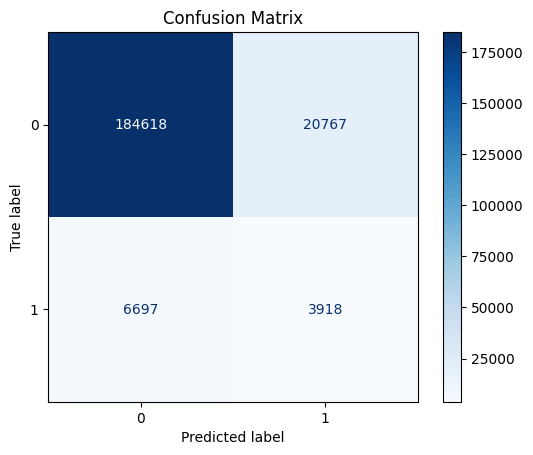

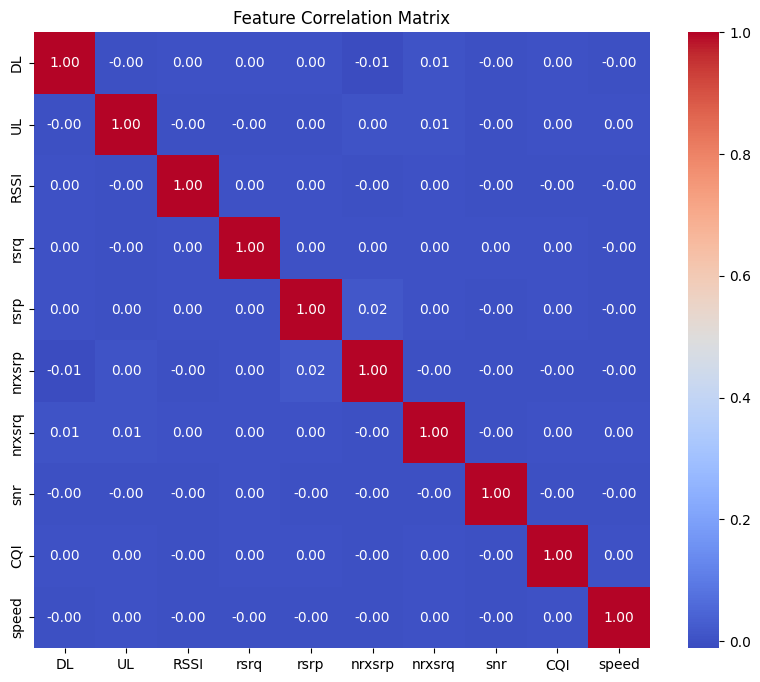

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rf_model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

# Correlation Matrix
plt.figure(figsize=(10, 8))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Feature Correlation Matrix")
plt.show()
